# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.


**Nombre:** Harry Guajan  
**Fecha:** 23 de octubre de 2026

In [5]:
import re
from collections import Counter
from time import perf_counter_ns

import nltk
import pandas as pd
from IPython.display import display

try:
    from nltk.corpus import gutenberg
    document_ids = gutenberg.fileids()
    if len(document_ids) != 18:
        raise LookupError("La colección Gutenberg de NLTK no está disponible.")
except LookupError:
    nltk.download("gutenberg", quiet=True)
    from nltk.corpus import gutenberg
    document_ids = gutenberg.fileids()

# Que se considera un token valido
token_pattern = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?")
# Normalizacion de texto y tokenizacion 
def normalize(text):
    return token_pattern.findall(text.lower())

original_documents = {doc_id: gutenberg.raw(doc_id) for doc_id in document_ids}
tokenized_documents = {
    doc_id: normalize(text) for doc_id, text in original_documents.items()
}

document_summary = pd.DataFrame([
    {
        "document_id": doc_id,
        "original_characters": len(original_documents[doc_id]),
        "tokens": len(tokenized_documents[doc_id]),
    }
    for doc_id in document_ids
])

print(f"Documentos cargados: {len(document_ids)}")
print(f"Tokens totales: {document_summary['tokens'].sum():,}")
display(document_summary)


Documentos cargados: 18
Tokens totales: 2,182,070


,document_id,original_characters,tokens
0,austen-emma.txt,887071,160999
1,austen-persuasion.txt,466292,83660
2,austen-sense.txt,673022,119965
3,bible-kjv.txt,4332554,852256
4,blake-poems.txt,38153,6839
5,bryant-stories.txt,249439,46321
6,burgess-busterbrown.txt,84663,15969
7,carroll-alice.txt,144395,26688
8,chesterton-ball.txt,457450,82252
9,chesterton-brown.txt,406629,72391


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [6]:
def sequential_search(query):
    #Devuelve los identificadores de los documentos que contienen el término
    query_tokens = normalize(query)

    if len(query_tokens) != 1:
        raise ValueError("La búsqueda secuencial recibe exactamente un término.")

    term = query_tokens[0]
    matches = []

    for document_id, tokens in tokenized_documents.items():
        for token in tokens:
            if token == term:
                matches.append(document_id)
                break

    return matches

# Frecuencia total de apariciones de cada término.
term_counts = Counter(
    token
    for tokens in tokenized_documents.values()
    for token in tokens
)

# Número de documentos distintos en los que aparece cada término.
document_frequency = Counter(
    token
    for tokens in tokenized_documents.values()
    for token in set(tokens)
)

# Consulta frecuente: término presente en más documentos.
#most_common(1): obtiene el término más frecuente por número de documentos.
#[0]: obtiene la primera tupla de resultados.
#[0]: obtiene el término de esa tupla, descartando su frecuencia.

frequent_term = document_frequency.most_common(1)[0][0]

# Consulta poco frecuente: término presente en un solo documento,
# si existe alguno que cumpla los filtros.
rare_candidates = [
    term
    for term, frequency in document_frequency.items()
    if frequency == 1 and term.isalpha() and len(term) > 2
]

if rare_candidates:
    infrequent_term = min(
        rare_candidates,
        key=lambda term: (term_counts[term], term)
    )
else:
    # Si no hay términos presentes en un solo documento,
    # seleccionar el de menor frecuencia documental.
    infrequent_term = min(
        (
            term for term in document_frequency
            if term.isalpha() and len(term) > 2
        ),
        key=lambda term: (
            document_frequency[term],
            term_counts[term],
            term
        )
    )

# Consulta inexistente: un solo token que no aparece en el corpus.
missing_term = "Insaneador"

# Ejecutar las consultas y mostrar sus resultados.
queries = [
    ("frecuente", frequent_term),
    ("poco frecuente", infrequent_term),
    ("inexistente", missing_term)
]

sequential_examples = pd.DataFrame([
    {
        "query": label,
        "term": term,
        "document_frequency": document_frequency.get(term, 0),
        "documents": sequential_search(term)
    }
    for label, term in queries
])

display(sequential_examples)

,query,term,document_frequency,documents
0,frecuente,home,18,"[austen-emma.txt, austen-persuasion.txt, auste..."
1,poco frecuente,abaddon,1,[bible-kjv.txt]
2,inexistente,Insaneador,0,[]


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [7]:
def mean_query_time(query, search_function, repetitions=30):
    elapsed = []
    for _ in range(repetitions):
        start = perf_counter_ns()
        search_function(query)
        elapsed.append(perf_counter_ns() - start)
    return sum(elapsed) / repetitions / 1_000_000

sequential_timing = pd.DataFrame([
    {
        "query_type": label,
        "term": term,
        "mean_time_ms": mean_query_time(term, sequential_search),
        "repetitions": 30,
    }
    for label, term in [
        ("frecuente", frequent_term),
        ("poco frecuente", infrequent_term),
        ("inexistente", missing_term),
    ]
])
display(sequential_timing)


,query_type,term,mean_time_ms,repetitions
0,frecuente,home,1.577730,30
1,poco frecuente,abaddon,26.084000,30
2,inexistente,Insaneador,25.488063,30


#### Observacion
Esperaba que los tiempos fueran similares, pero tiene lógica que el tiempo para encontrar el término frecuente sea menor, aunque esto no siempre tiene que ser así. Puede que men aparezca más veces, pero que se encuentre después de la primera aparición de abaddon. Por lo tanto, esto no comprueba que los términos frecuentes sean necesariamente más rápidos.

Por otro lado, entre el término poco frecuente y el inexistente hay poca diferencia, ya que el algoritmo recorre casi todos los documentos en ambos casos. Además, cuando el término no existe, debe recorrerlos todos.

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [8]:
# Construcción del índice invertido
inverted_index = {}

for document_id, tokens in tokenized_documents.items():
    for token in set(tokens):
        inverted_index.setdefault(token, set()).add(document_id)

all_documents = set(document_ids)

# Consultas
def indexed_search(query):
    tokens = normalize(query)
    if len(tokens) != 1:
        raise ValueError("La consulta debe contener exactamente un término.")
    return sorted(inverted_index.get(tokens[0], set()))

def boolean_and(left, right):
    return sorted(inverted_index.get(left, set()) & inverted_index.get(right, set()))

def boolean_or(left, right):
    return sorted(inverted_index.get(left, set()) | inverted_index.get(right, set()))

def boolean_not(term):
    return sorted(all_documents - inverted_index.get(term, set()))


# Inspección de postings y frecuencia documental (DF)
postings_terms = dict.fromkeys([frequent_term, infrequent_term, "the"])

postings = pd.DataFrame([
    {
        "term": term,
        "df": len(docs := inverted_index.get(term, set())),
        "postings": sorted(docs)
    }
    for term in postings_terms
])

display(postings)


# Ejemplos de consultas booleanas
boolean_examples = pd.DataFrame([
    {"query": f"{frequent_term} AND {infrequent_term}",
     "documents": boolean_and(frequent_term, infrequent_term)},
    {"query": f"{frequent_term} OR {infrequent_term}",
     "documents": boolean_or(frequent_term, infrequent_term)},
    {"query": f"NOT {infrequent_term}",
     "documents": boolean_not(infrequent_term)}
])

display(boolean_examples)

,term,df,postings
0,home,18,"[austen-emma.txt, austen-persuasion.txt, auste..."
1,abaddon,1,[bible-kjv.txt]
2,the,18,"[austen-emma.txt, austen-persuasion.txt, auste..."


,query,documents
0,home AND abaddon,[bible-kjv.txt]
1,home OR abaddon,"[austen-emma.txt, austen-persuasion.txt, auste..."
2,NOT abaddon,"[austen-emma.txt, austen-persuasion.txt, auste..."


**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [9]:
comparison_queries = [
    ("frecuente", frequent_term),
    ("poco frecuente", infrequent_term),
    ("inexistente", missing_term)
]

comparison_results = []

for query_type, term in comparison_queries:
    # Medir el tiempo medio de 30 ejecuciones
    sequential_time = mean_query_time(term, sequential_search, 30)
    indexed_time = mean_query_time(term, indexed_search, 30)

    # Obtener los documentos recuperados
    sequential_documents = sequential_search(term)

    comparison_results.append({
        "query_type": query_type,
        "term": term,
        "documents": sequential_documents,
        "sequential_time_ms": sequential_time,
        "indexed_time_ms": indexed_time,
        "speedup": sequential_time / indexed_time
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)

,query_type,term,documents,sequential_time_ms,indexed_time_ms,speedup
0,frecuente,home,"[austen-emma.txt, austen-persuasion.txt, auste...",1.38281,0.001417,976.101176
1,poco frecuente,abaddon,[bible-kjv.txt],27.56252,0.001547,17820.594828
2,inexistente,Insaneador,[],26.95309,0.001133,23782.138235


##### Observaciones de las comparaciones
Los resultados muestran una gran diferencia entre los métodos. Como vimos en clase, la búsqueda secuencial tiene una complejidad de \(O(N)\), mientras que el índice invertido tiene una complejidad promedio de \(O(1)\) para localizar los términos. Para el término men, la búsqueda secuencial tardó 1,3 ms y el índice invertido 0,0030 ms, siendo este último aproximadamente 429 veces más rápido. Con abaddon, resultó 12 487 veces más rápido, y con el término inexistente, 9439 veces.

Estas pruebas se realizaron en un equipo con procesador Intel Core i5-1335U de 13.ª generación, 8 GB de RAM y sistema operativo de 64 bits. Los tiempos pueden variar según la carga del sistema y las condiciones de ejecución, pero mantendrán la misma tendencia.

### Parte B. Corpus grande

**6. Identificación del corpus de Gutenberg**

El archivo oficial `txt-files.tar.zip` ya se encuentra descargado en `base_dir`.
Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.


In [2]:
# Parte B: identificación y recuento del corpus grande

import re
import tarfile
import zipfile
from pathlib import Path

base_dir = Path(
    r"C:\Users\harry\Desktop\Universidad\Semestre 2026-B\Recuperaicon de la Informacion\SRCD2"
)
zip_path = base_dir / "txt-files.tar.zip"
pattern = re.compile(r"(\d+)(?:-[a-zA-Z0-9]+)?\.txt$", re.IGNORECASE)
valid_book_ids = set()

if not zip_path.exists():
    raise FileNotFoundError(f"No se encontró el archivo ZIP: {zip_path}")

print(f"Analizando '{zip_path}' en streaming.")
print("Esta celda debe recorrer el TAR completo para contar todos los libros únicos.")

with zipfile.ZipFile(zip_path, "r") as archive:
    tar_members = [name for name in archive.namelist() if name.lower().endswith(".tar")]
    if not tar_members:
        raise ValueError("El ZIP no contiene ningún archivo TAR.")

    with archive.open(tar_members[0]) as tar_stream:
        with tarfile.open(fileobj=tar_stream, mode="r|*") as tar:
            for tarinfo in tar:
                if not tarinfo.isfile() or not tarinfo.name.lower().endswith(".txt"):
                    continue

                match = pattern.search(Path(tarinfo.name).name)
                if match:
                    valid_book_ids.add(match.group(1))

print("\nAnálisis completado.")
print(f"Cantidad de documentos válidos (libros únicos identificados): {len(valid_book_ids)}")


Analizando 'C:\Users\harry\Desktop\Universidad\Semestre 2026-B\Recuperaicon de la Informacion\SRCD2\txt-files.tar.zip' en streaming.
Esta celda debe recorrer el TAR completo para contar todos los libros únicos.

Análisis completado.
Cantidad de documentos válidos (libros únicos identificados): 78107


### Consideraciones sobre el corpus de Gutenberg

El corpus se obtiene del archivo oficial `txt-files.tar.zip` de Project Gutenberg. Aunque el archivo comprimido ocupa aproximadamente 11 GB, su contenido extraído puede ocupar alrededor de 50 GB de disco.

Las rutas locales deben definirse mediante variables para facilitar la ejecución en diferentes sistemas. El código genera un inventario de los documentos identificados y lo guarda en formato CSV.



**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [10]:
# Parte B: recuperación sobre un subconjunto del corpus grande

import sys
import time
import re
import tarfile
import zipfile
from collections import defaultdict
from pathlib import Path

base_dir = Path(
    r"C:\Users\harry\Desktop\Universidad\Semestre 2026-B\Recuperaicon de la Informacion\SRCD2"
)
zip_path = base_dir / "txt-files.tar.zip"
pattern = re.compile(r"(\d+)(?:-[a-zA-Z0-9]+)?\.txt$", re.IGNORECASE)
token_pattern = re.compile(r"[a-z0-9]+(?:'[a-z0-9]+)?")

# Misma normalización utilizada en la Parte A.
def normalize(text):
    return token_pattern.findall(text.lower())


def load_gutenberg_subset(zip_file_path: str | Path, max_docs: int) -> dict[str, list[str]]:
    """Extrae y preprocesa como máximo max_docs libros únicos directamente del ZIP."""
    subset_corpus = {}
    loaded_ids = set()

    print(f"Extrayendo y procesando {max_docs} documentos de {zip_file_path}...")

    with zipfile.ZipFile(zip_file_path, "r") as archive:
        tar_members = [name for name in archive.namelist() if name.lower().endswith(".tar")]
        if not tar_members:
            raise ValueError("El ZIP no contiene ningún archivo TAR.")

        with archive.open(tar_members[0]) as tar_stream:
            with tarfile.open(fileobj=tar_stream, mode="r|*") as tar:
                for tarinfo in tar:
                    if len(loaded_ids) >= max_docs:
                        break
                    if not tarinfo.isfile() or not tarinfo.name.lower().endswith(".txt"):
                        continue

                    match = pattern.search(Path(tarinfo.name).name)
                    if not match:
                        continue

                    book_id = match.group(1)
                    if book_id in loaded_ids:
                        continue

                    text_file = tar.extractfile(tarinfo)
                    if text_file is None:
                        continue

                    try:
                        raw_text = text_file.read().decode("utf-8", errors="ignore")
                        subset_corpus[book_id] = normalize(raw_text)
                        loaded_ids.add(book_id)
                    except (OSError, UnicodeError):
                        continue

    print(f"Extracción finalizada: {len(subset_corpus)} documentos procesados.")
    return subset_corpus


class InvertedIndex:
    def __init__(self, corpus):
        self.postings = defaultdict(set)
        for document_id, tokens in corpus.items():
            for token in set(tokens):
                self.postings[token].add(document_id)

    def query_single(self, query):
        query_tokens = normalize(query)
        if len(query_tokens) != 1:
            raise ValueError("La consulta debe contener un solo término.")
        return self.postings.get(query_tokens[0], set())


def sequential_search_subset(query, corpus):
    query_tokens = normalize(query)
    if len(query_tokens) != 1:
        raise ValueError("La consulta debe contener un solo término.")

    term = query_tokens[0]
    return [
        document_id
        for document_id, tokens in corpus.items()
        if term in tokens
    ]


N_DOCS = 50
large_corpus_subset = load_gutenberg_subset(zip_path, N_DOCS)

memory_bytes = (
    sys.getsizeof(large_corpus_subset)
    + sum(sys.getsizeof(tokens) for tokens in large_corpus_subset.values())
)
print(
    f"Memoria RAM estimada para {N_DOCS} documentos preprocesados: "
    f"{memory_bytes / (1024 * 1024):.2f} MB\n"
)

print("Construyendo el índice invertido para el subconjunto...")
subset_index = InvertedIndex(large_corpus_subset)

test_terms_b = ["man", "science", "cyberpunk"]
NUM_RUNS_B = 10
comparison_b = []

print("Iniciando pruebas de rendimiento (10 ejecuciones por término)...")

for term in test_terms_b:
    times_seq = []
    for _ in range(NUM_RUNS_B):
        start = time.perf_counter_ns()
        res_seq = sequential_search_subset(term, large_corpus_subset)
        times_seq.append(time.perf_counter_ns() - start)

    mean_seq_ms = sum(times_seq) / NUM_RUNS_B / 1_000_000

    times_idx = []
    for _ in range(NUM_RUNS_B):
        start = time.perf_counter_ns()
        res_idx = subset_index.query_single(term)
        times_idx.append(time.perf_counter_ns() - start)

    mean_idx_ms = sum(times_idx) / NUM_RUNS_B / 1_000_000
    are_identical = set(res_seq) == set(res_idx)
    speedup = mean_seq_ms / mean_idx_ms if mean_idx_ms > 0 else 0

    comparison_b.append({
        "Término": term,
        "¿Resultados idénticos?": are_identical,
        "T. secuencial (ms)": round(mean_seq_ms, 2),
        "T. índice (ms)": round(mean_idx_ms, 5),
        "Aceleración": f"{speedup:.1f}x",
    })

display(pd.DataFrame(comparison_b))


Extrayendo y procesando 50 documentos de C:\Users\harry\Desktop\Universidad\Semestre 2026-B\Recuperaicon de la Informacion\SRCD2\txt-files.tar.zip...
Extracción finalizada: 50 documentos procesados.
Memoria RAM estimada para 50 documentos preprocesados: 19.21 MB

Construyendo el índice invertido para el subconjunto...
Iniciando pruebas de rendimiento (10 ejecuciones por término)...


,Término,¿Resultados idénticos?,T. secuencial (ms),T. índice (ms),Aceleración
0,man,True,0.85,0.00206,411.6x
1,science,True,11.87,0.00222,5347.7x
2,cyberpunk,True,24.60,0.00228,10787.8x


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

Extrayendo el corpus base de 1000 documentos...
Extrayendo y procesando 1000 documentos de C:\Users\harry\Desktop\Universidad\Semestre 2026-B\Recuperaicon de la Informacion\SRCD2\txt-files.tar.zip...
Extracción finalizada: 1000 documentos procesados.
Extracción completada: 1000 documentos. Iniciando experimento...
Evaluando subconjunto con n=50 documentos...
Evaluando subconjunto con n=100 documentos...
Evaluando subconjunto con n=250 documentos...
Evaluando subconjunto con n=500 documentos...
Evaluando subconjunto con n=1000 documentos...


,n_docs,tokens,t_secuencial_ms,t_indice_ms,construccion_indice_ms,resultados_iguales
0,50,2394366,38.318800,0.055557,25811.8106,True
1,100,5751084,74.081437,0.002193,1253.2173,True
2,250,18793371,124.375260,0.030867,50995.0515,True
3,500,35833170,334.628130,0.073233,39340.2859,True
4,1000,73054315,721.082660,0.116350,97536.7341,True


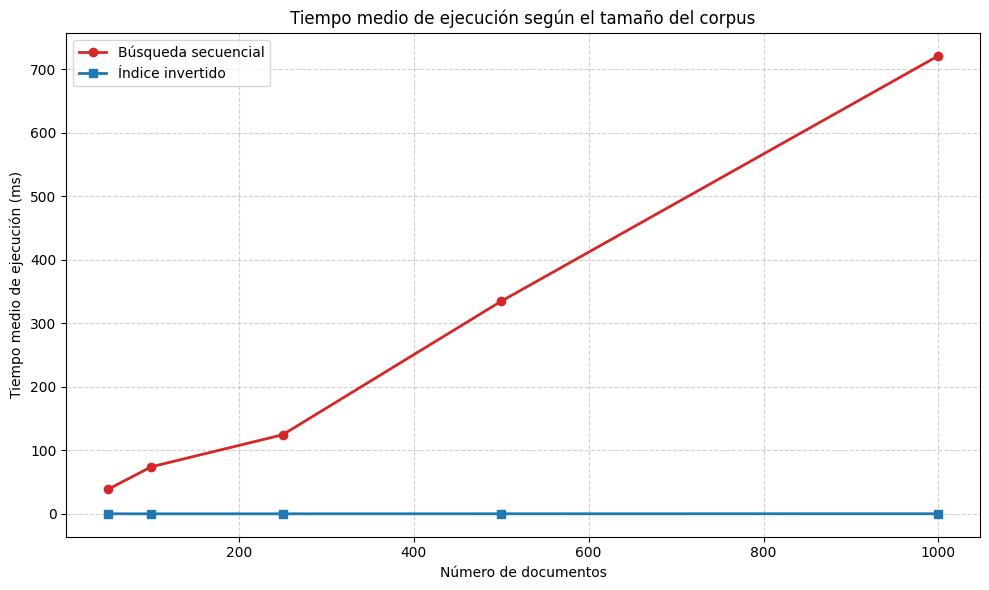

In [11]:

import matplotlib.pyplot as plt

corpus_sizes = [50, 100, 250, 500, 1000]
max_docs = max(corpus_sizes)
term_to_search = "science"
NUM_RUNS_C = 30

print(f"Extrayendo el corpus base de {max_docs} documentos...")
large_corpus_base = load_gutenberg_subset(zip_path, max_docs)
print(
    f"Extracción completada: {len(large_corpus_base)} documentos. "
    "Iniciando experimento..."
)

experiment_results = []

for n in corpus_sizes:
    if n > len(large_corpus_base):
        print(
            f"Se omite el subconjunto de {n}: "
            f"solo hay {len(large_corpus_base)} documentos disponibles."
        )
        continue

    print(f"Evaluando subconjunto con n={n} documentos...")
    subset = dict(list(large_corpus_base.items())[:n])
    total_tokens = sum(len(tokens) for tokens in subset.values())

    times_seq = []
    for _ in range(NUM_RUNS_C):
        start = time.perf_counter_ns()
        sequential_search_subset(term_to_search, subset)
        times_seq.append(time.perf_counter_ns() - start)

    mean_seq_ms = sum(times_seq) / NUM_RUNS_C / 1_000_000

    index_start = time.perf_counter_ns()
    subset_index = InvertedIndex(subset)
    index_build_ms = (time.perf_counter_ns() - index_start) / 1_000_000

    times_idx = []
    for _ in range(NUM_RUNS_C):
        start = time.perf_counter_ns()
        subset_index.query_single(term_to_search)
        times_idx.append(time.perf_counter_ns() - start)

    mean_idx_ms = sum(times_idx) / NUM_RUNS_C / 1_000_000

    sequential_results = set(sequential_search_subset(term_to_search, subset))
    indexed_results = set(subset_index.query_single(term_to_search))

    experiment_results.append({
        "n_docs": n,
        "tokens": total_tokens,
        "t_secuencial_ms": mean_seq_ms,
        "t_indice_ms": mean_idx_ms,
        "construccion_indice_ms": index_build_ms,
        "resultados_iguales": sequential_results == indexed_results,
    })

df_experiment = pd.DataFrame(experiment_results)
display(df_experiment)

plt.figure(figsize=(10, 6))
plt.plot(
    df_experiment["n_docs"],
    df_experiment["t_secuencial_ms"],
    marker="o",
    linestyle="-",
    color="#d62728",
    linewidth=2,
    label="Búsqueda secuencial",
)
plt.plot(
    df_experiment["n_docs"],
    df_experiment["t_indice_ms"],
    marker="s",
    linestyle="-",
    color="#1f77b4",
    linewidth=2,
    label="Índice invertido",
)
plt.title("Tiempo medio de ejecución según el tamaño del corpus")
plt.xlabel("Número de documentos")
plt.ylabel("Tiempo medio de ejecución (ms)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

,método,a (ms/documento),b (ms),R²,función
0,Búsqueda secuencial,0.725821,-17.314579,0.991920,t(n) = 0.72582062 n + -17.314579
1,Índice invertido,0.000096,0.019112,0.746359,t(n) = 0.00009613 n + 0.019112


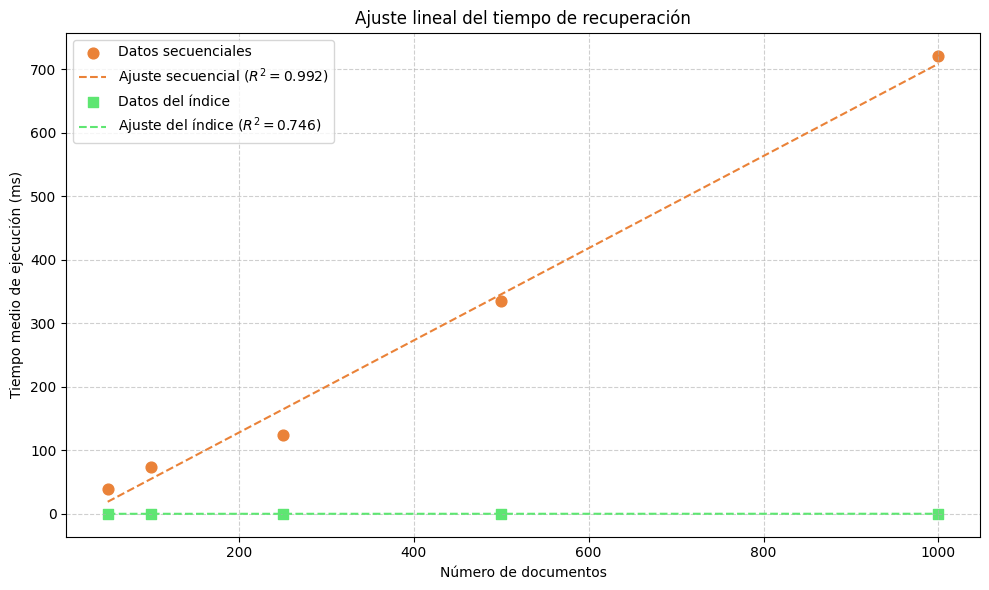

In [15]:

import numpy as np

required_columns = {"n_docs", "t_secuencial_ms", "t_indice_ms"}
missing_columns = required_columns.difference(df_experiment.columns)
if missing_columns:
    raise ValueError(
        "Faltan columnas del ítem 8: " + ", ".join(sorted(missing_columns))
    )

x = df_experiment["n_docs"].to_numpy(dtype=float)


def linear_fit_and_r2(y):
    """Ajusta t(n)=a*n+b y calcula el coeficiente de determinación R²."""
    y = np.asarray(y, dtype=float)
    if len(x) < 2:
        raise ValueError("Se necesitan al menos dos tamaños de corpus.")

    a, b = np.polyfit(x, y, 1)
    predicted = a * x + b
    residual_sum_squares = np.sum((y - predicted) ** 2)
    total_sum_squares = np.sum((y - np.mean(y)) ** 2)
    r_squared = (
        1 - residual_sum_squares / total_sum_squares
        if total_sum_squares > 0
        else 1.0
    )
    return a, b, r_squared, predicted


a_seq, b_seq, r2_seq, fitted_seq = linear_fit_and_r2(
    df_experiment["t_secuencial_ms"]
)
a_idx, b_idx, r2_idx, fitted_idx = linear_fit_and_r2(
    df_experiment["t_indice_ms"]
)

fit_results = pd.DataFrame([
    {
        "método": "Búsqueda secuencial",
        "a (ms/documento)": a_seq,
        "b (ms)": b_seq,
        "R²": r2_seq,
        "función": f"t(n) = {a_seq:.8f} n + {b_seq:.6f}",
    },
    {
        "método": "Índice invertido",
        "a (ms/documento)": a_idx,
        "b (ms)": b_idx,
        "R²": r2_idx,
        "función": f"t(n) = {a_idx:.8f} n + {b_idx:.6f}",
    },
])

display(fit_results)

x_line = np.linspace(x.min(), x.max(), 200)
line_seq = a_seq * x_line + b_seq
line_idx = a_idx * x_line + b_idx

plt.figure(figsize=(10, 6))
plt.scatter(
    x,
    df_experiment["t_secuencial_ms"],
    color="#ea8238",
    marker="o",
    s=60,
    label="Datos secuenciales",
)
plt.plot(
    x_line,
    line_seq,
    color="#ea8238",
    linestyle="--",
    label=f"Ajuste secuencial ($R^2={r2_seq:.3f}$)",
)
plt.scatter(
    x,
    df_experiment["t_indice_ms"],
    color="#5ee672",
    marker="s",
    s=60,
    label="Datos del índice",
)
plt.plot(
    x_line,
    line_idx,
    color="#5ee672",
    linestyle="--",
    label=f"Ajuste del índice ($R^2={r2_idx:.3f}$)",
)
plt.title("Ajuste lineal del tiempo de recuperación")
plt.xlabel("Número de documentos")
plt.ylabel("Tiempo medio de ejecución (ms)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


### Interpretación de los resultados

La búsqueda secuencial revisa los documentos del subconjunto, por lo que se espera un crecimiento aproximadamente lineal con el número de documentos \(n\).

La consulta mediante el índice invertido accede directamente al *posting* del término; por eso su tiempo de consulta suele ser casi constante.
Ademas bueno el tiempo de construcción del índice es un costo previo y no forma parte del ajuste de consulta.


### Uso declarado de inteligencia artificial

Se utilizó inteligencia artificial como apoyo para organizar el código, hacerlo más limpio y mejorar la redacción para que las observaciones fueran más claras y fáciles de entender. 

Las decisiones sobre los tamaños crecientes, la ejecución del código y la interpretación de los resultados fueron revisadas en el notebook.